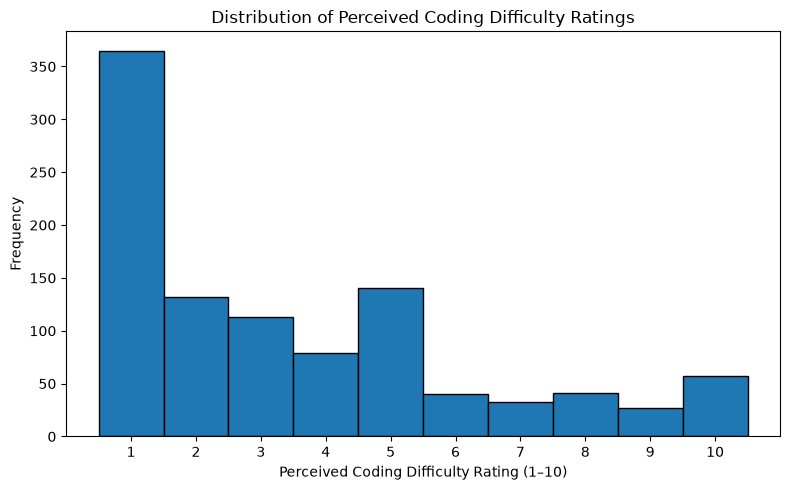

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the cleaned dataset
PATH = r"actual_cleaned_outlier_removed.csv"
df = pd.read_csv(PATH)

# 2. Extract the dependent variable
ratings = df["difficulty_1to10"].dropna()

# 3. Plot the histogram
plt.figure(figsize=(8, 5))

plt.hist(
    ratings,
    bins=[i - 0.5 for i in range(1, 12)],
    edgecolor="black"
)

plt.xticks(range(1, 11))
plt.xlabel("Perceived Coding Difficulty Rating (1–10)")
plt.ylabel("Frequency")
plt.title("Distribution of Perceived Coding Difficulty Ratings")
plt.tight_layout()

# 4. Save the figure for your research paper
plt.savefig("Figure_1_Difficulty_Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

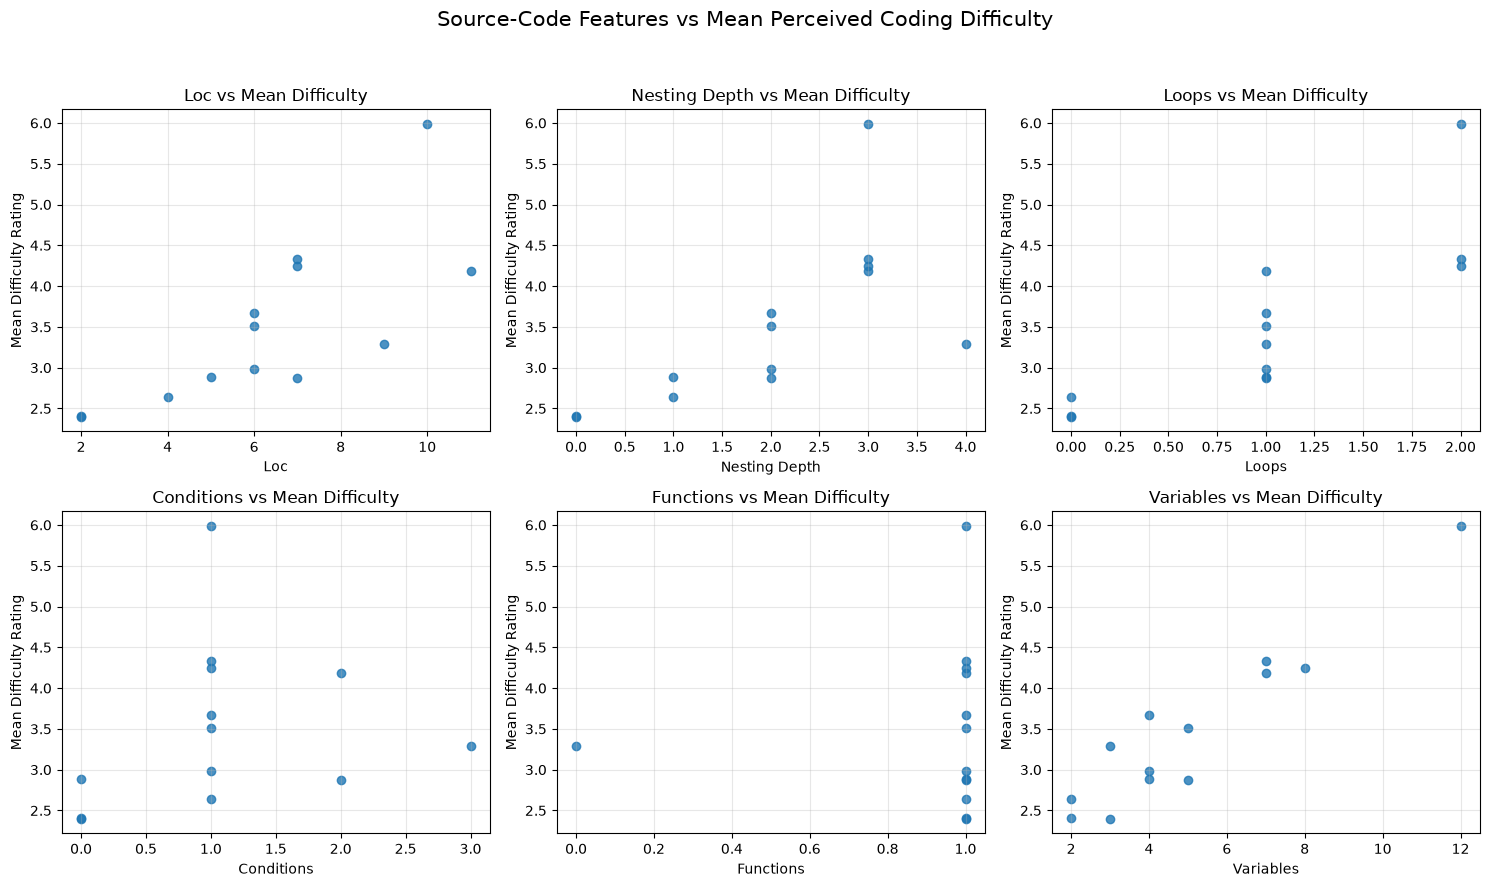

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import math

# 1. Load the cleaned dataset
PATH = r"actual_cleaned_outlier_removed.csv"
df = pd.read_csv(PATH)

# 2. Source-code features
features = [
    "LOC",
    "nesting_depth",
    "loops",
    "conditions",
    "functions",
    "variables"
]

# 3. Calculate mean difficulty rating for each snippet
snippet_means = (
    df.groupby("snippet_id")
      .agg(
          mean_difficulty=("difficulty_1to10", "mean"),
          **{feature: (feature, "first") for feature in features}
      )
      .reset_index()
)

# 4. Create a single image with six scatter plots
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, feature in zip(axes, features):
    ax.scatter(
        snippet_means[feature],
        snippet_means["mean_difficulty"],
        alpha=0.8
    )

    ax.set_xlabel(feature.replace("_", " ").title())
    ax.set_ylabel("Mean Difficulty Rating")
    ax.set_title(f"{feature.replace('_', ' ').title()} vs Mean Difficulty")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Source-Code Features vs Mean Perceived Coding Difficulty",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# 5. Save all six plots as one high-resolution image
plt.savefig(
    "Figure_3_Features_vs_Mean_Difficulty.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

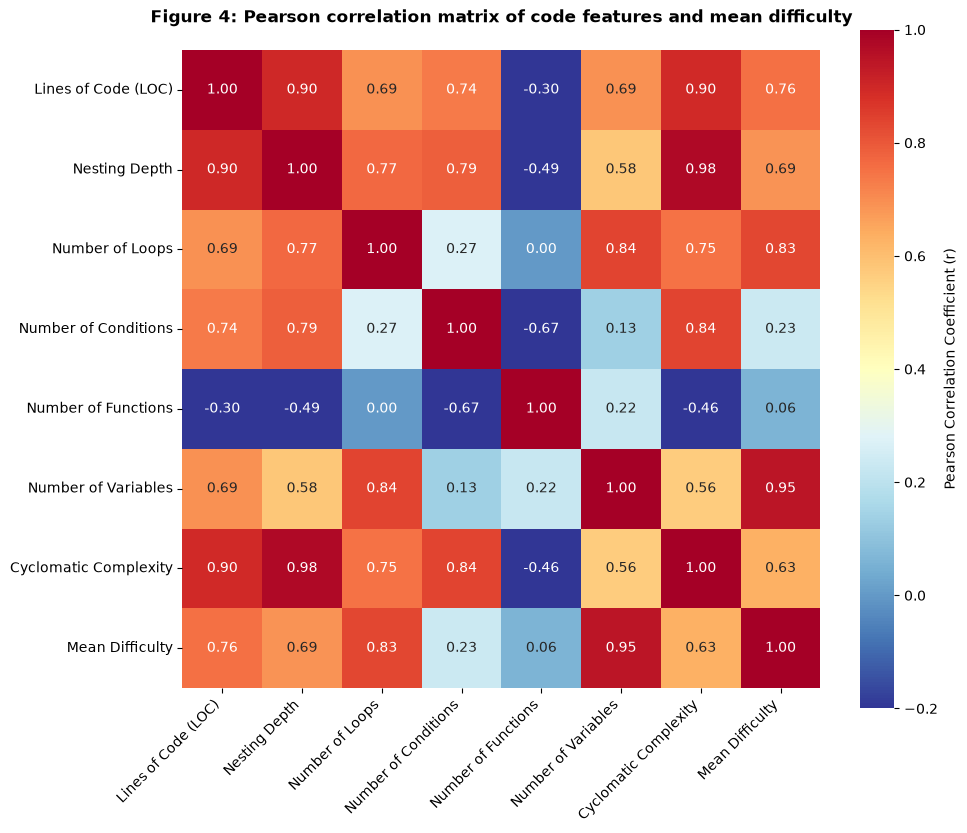

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load cleaned dataset
PATH = r"actual_cleaned_outlier_removed.csv"
df = pd.read_csv(PATH)

# 2. Seven source-code features
features = [
    "LOC",
    "nesting_depth",
    "loops",
    "conditions",
    "functions",
    "variables",
    "cyclomatic_complexity"
]

# 3. Calculate mean difficulty rating for each snippet
snippet_data = (
    df.groupby("snippet_id")
      .agg(
          mean_difficulty=("difficulty_1to10", "mean"),
          **{feature: (feature, "first") for feature in features}
      )
      .reset_index()
)

# 4. Calculate correlation matrix
corr_data = snippet_data[features + ["mean_difficulty"]]
corr_matrix = corr_data.corr(method="pearson")

# --- MAPPING FOR EXACT LABELS ---
labels_map = {
    "LOC": "Lines of Code (LOC)",
    "nesting_depth": "Nesting Depth",
    "loops": "Number of Loops",
    "conditions": "Number of Conditions",
    "functions": "Number of Functions",
    "variables": "Number of Variables",
    "cyclomatic_complexity": "Cyclomatic Complexity",
    "mean_difficulty": "Mean Difficulty"
}
corr_matrix = corr_matrix.rename(index=labels_map, columns=labels_map)

# 5. Create colored heatmap
plt.figure(figsize=(10, 8.5))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    vmin=-0.2,          # Updated to match image baseline
    vmax=1.0,           # Updated to match image maximum
    center=0.4,         # Adjusted center slightly for matching color transitions
    square=True,
    linewidths=0,       # No lines between cells to match the seamless look
    cbar_kws={"label": "Pearson Correlation Coefficient (r)"} # Added (r)
)

# Set the title exactly as shown in Figure 4
plt.title(
    "Figure 4: Pearson correlation matrix of code features and mean difficulty",
    fontsize=12,
    fontweight="bold",
    pad=20
)

# Rotate labels precisely as shown in the image
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# 6. Save as a single high-resolution image
plt.savefig(
    "Figure_Correlation_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [5]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


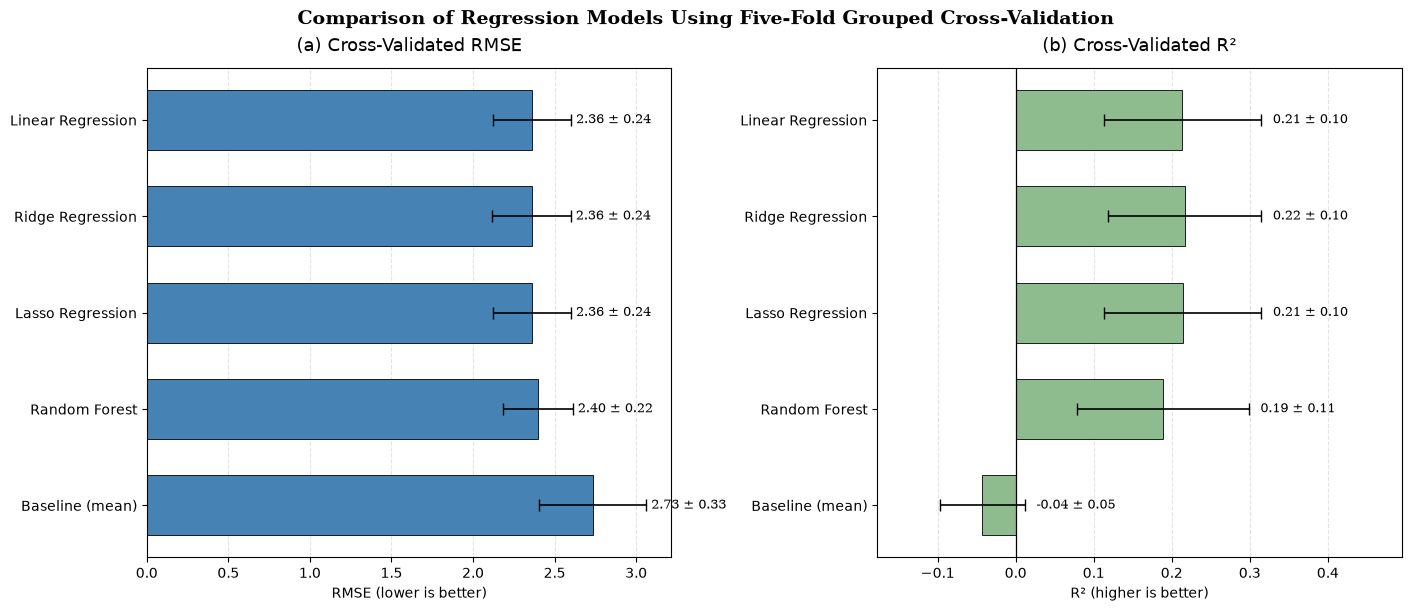

In [8]:
# --------------------------------------------------
# 5. Publication-quality model performance figure
# --------------------------------------------------
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True
)

models_order = results_df["Model"].tolist()
y_pos = np.arange(len(models_order))

# Consistent professional styling
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11
})

# Panel 1: RMSE
axes[0].barh(
    y_pos,
    results_df["RMSE_mean"],
    xerr=results_df["RMSE_std"],
    capsize=4,
    height=0.62,
    color="steelblue",
    edgecolor="black",
    linewidth=0.6,
    error_kw={"elinewidth": 1.2}
)

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(models_order)
axes[0].invert_yaxis()
axes[0].set_xlabel("RMSE (lower is better)")
axes[0].set_title("(a) Cross-Validated RMSE", pad=12)
axes[0].grid(axis="x", linestyle="--", alpha=0.35)
axes[0].set_axisbelow(True)

# Add mean ± standard deviation labels
for i, (mean, std) in enumerate(
    zip(results_df["RMSE_mean"], results_df["RMSE_std"])
):
    axes[0].text(
        mean + std + 0.03,
        i,
        f"{mean:.2f} ± {std:.2f}",
        va="center",
        fontsize=9
    )

# Panel 2: R-squared
axes[1].barh(
    y_pos,
    results_df["R2_mean"],
    xerr=results_df["R2_std"],
    capsize=4,
    height=0.62,
    color="darkseagreen",
    edgecolor="black",
    linewidth=0.6,
    error_kw={"elinewidth": 1.2}
)

axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(models_order)
axes[1].invert_yaxis()
axes[1].set_xlabel("R² (higher is better)")
axes[1].set_title("(b) Cross-Validated R²", pad=12)
axes[1].axvline(0, color="black", linewidth=0.9)
axes[1].grid(axis="x", linestyle="--", alpha=0.35)
axes[1].set_axisbelow(True)

# Adjust R² axis to include negative values and error bars
r2_min = min(
    0,
    (results_df["R2_mean"] - results_df["R2_std"]).min()
)
r2_max = (results_df["R2_mean"] + results_df["R2_std"]).max()
axes[1].set_xlim(r2_min - 0.08, r2_max + 0.18)

for i, (mean, std) in enumerate(
    zip(results_df["R2_mean"], results_df["R2_std"])
):
    axes[1].text(
        mean + std + 0.015,
        i,
        f"{mean:.2f} ± {std:.2f}",
        va="center",
        fontsize=9
    )

fig.suptitle(
    "Comparison of Regression Models Using Five-Fold Grouped Cross-Validation",
    fontsize=14,
    fontweight="bold"
)

# Save high-resolution figures for the research paper
fig.savefig(
    "Figure_Model_Performance_CV.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    "Figure_Model_Performance_CV.pdf",
    bbox_inches="tight"
)

plt.show()

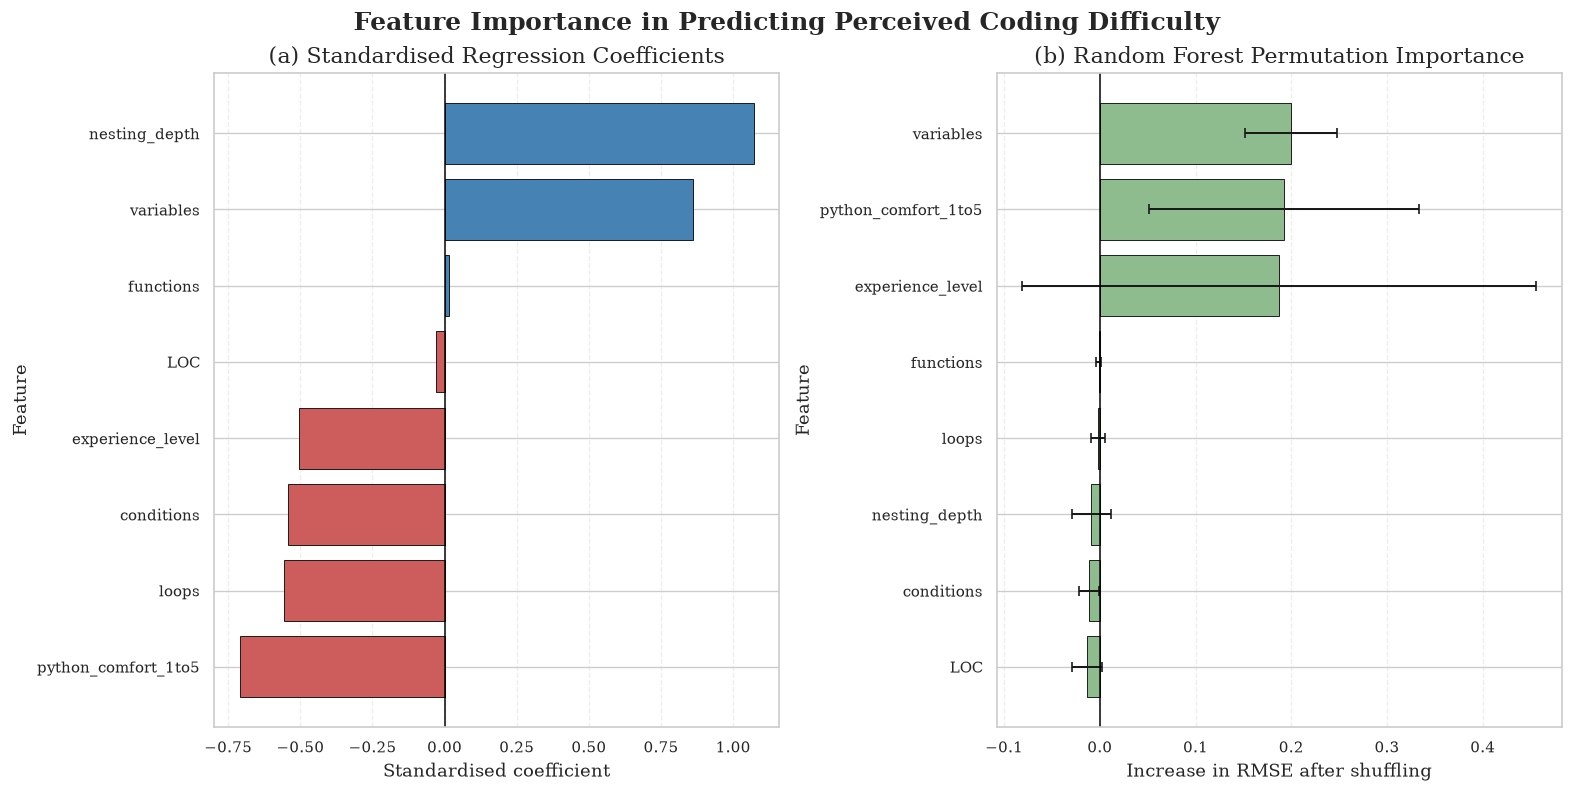

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# One combined, publication-quality figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6.5),
    constrained_layout=True
)

fig.suptitle(
    "Feature Importance in Predicting Perceived Coding Difficulty",
    fontsize=15,
    fontweight="bold"
)

# ------------------------------------------
# Left panel: Standardised Ridge coefficients
# ------------------------------------------
coef_plot = coefficients.sort_values("Coefficient").copy()

axes[0].barh(
    coef_plot["Feature"],
    coef_plot["Coefficient"],
    color=[
        "steelblue" if x >= 0 else "indianred"
        for x in coef_plot["Coefficient"]
    ],
    edgecolor="black",
    linewidth=0.5
)

axes[0].axvline(0, color="black", linewidth=0.9)
axes[0].set_title("(a) Standardised Regression Coefficients")
axes[0].set_xlabel("Standardised coefficient")
axes[0].set_ylabel("Feature")

# ------------------------------------------
# Right panel: Random Forest permutation importance
# ------------------------------------------
perm_plot = summary.sort_values("mean").copy()

axes[1].barh(
    perm_plot["Feature"],
    perm_plot["mean"],
    xerr=perm_plot["std"],
    color="darkseagreen",
    edgecolor="black",
    linewidth=0.5,
    capsize=3
)

axes[1].axvline(0, color="black", linewidth=0.9)
axes[1].set_title("(b) Random Forest Permutation Importance")
axes[1].set_xlabel("Increase in RMSE after shuffling")
axes[1].set_ylabel("Feature")

# Consistent typography
for ax in axes:
    ax.tick_params(axis="both", labelsize=9)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

# Save as one high-resolution image for Word
fig.savefig(
    "Figure_Feature_Importance_Combined.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Also save a vector version for crisp printing
fig.savefig(
    "Figure_Feature_Importance_Combined.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Random Forest — unseen-snippet evaluation
R²:   0.287
MAE:  1.786
RMSE: 2.305


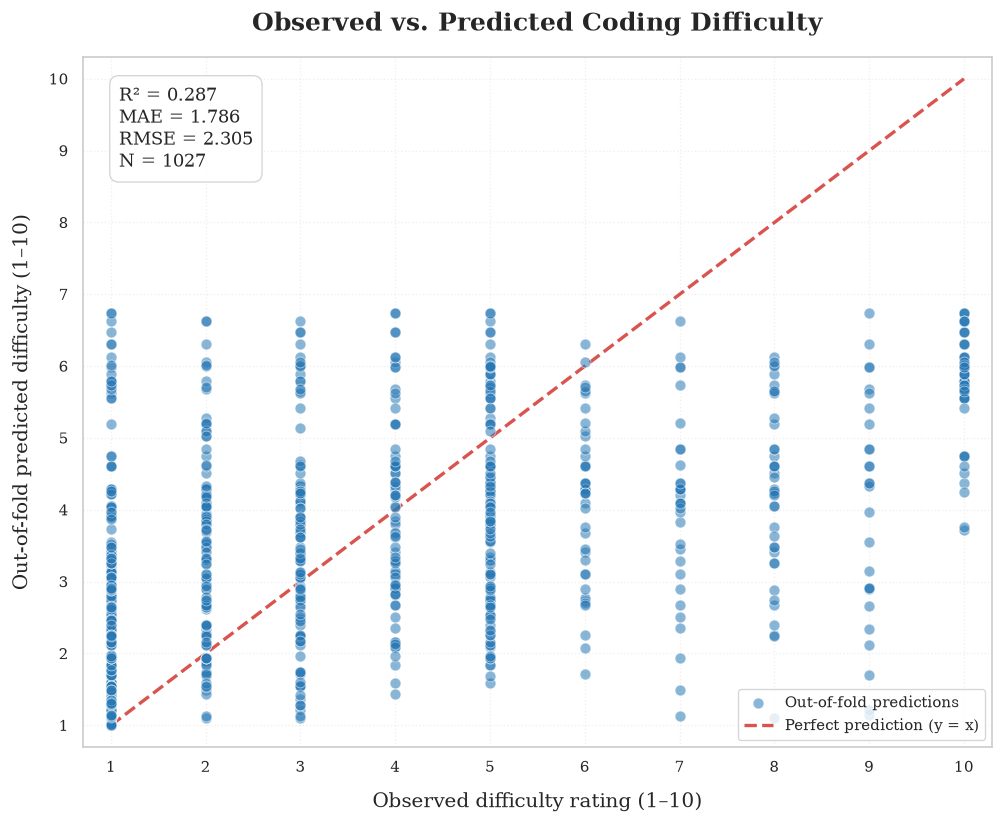

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Load the same dataset
# --------------------------------------------------
df = pd.read_csv("actual_cleaned_outlier_removed.csv")

FEATURES = [
    "LOC",
    "nesting_depth",
    "loops",
    "conditions",
    "functions",
    "variables",
    "cyclomatic_complexity",
    "experience_level",
    "python_comfort_1to5"
]

TARGET = "difficulty_1to10"

df = df.dropna(
    subset=FEATURES + [TARGET, "snippet_id", "participant_code"]
).copy()

X = df[FEATURES]
y = df[TARGET].astype(float)
groups = df["snippet_id"]

# --------------------------------------------------
# 2. Reproduce your original Random Forest
# --------------------------------------------------
logo = LeaveOneGroupOut()
oof_predictions = np.full(len(df), np.nan)

for train_idx, test_idx in logo.split(X, y, groups=groups):
    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    oof_predictions[test_idx] = model.predict(X.iloc[test_idx])

valid = np.isfinite(oof_predictions)

observed = y.to_numpy()[valid]
predicted = oof_predictions[valid]

mae = mean_absolute_error(observed, predicted)
rmse = np.sqrt(mean_squared_error(observed, predicted))
r2 = r2_score(observed, predicted)

print("Random Forest — unseen-snippet evaluation")
print(f"R²:   {r2:.3f}")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

# --------------------------------------------------
# 3. Publication-quality scatter plot
# --------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12
})

fig, ax = plt.subplots(figsize=(8.5, 7))

ax.scatter(
    observed,
    predicted,
    s=42,
    alpha=0.55,
    color="#2878B5",
    edgecolors="white",
    linewidths=0.5,
    label="Out-of-fold predictions",
    zorder=3
)

# Perfect-prediction line
ax.plot(
    [1, 10],
    [1, 10],
    linestyle="--",
    color="#D9534F",
    linewidth=2,
    label="Perfect prediction (y = x)",
    zorder=2
)

ax.set_xlim(0.7, 10.3)
ax.set_ylim(0.7, 10.3)
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))

ax.set_xlabel("Observed difficulty rating (1–10)", labelpad=10)
ax.set_ylabel("Out-of-fold predicted difficulty (1–10)", labelpad=10)

ax.set_title(
    "Observed vs. Predicted Coding Difficulty",
    fontweight="bold",
    pad=16
)

# Metrics calculated from the plotted predictions
stats = (
    f"R² = {r2:.3f}\n"
    f"MAE = {mae:.3f}\n"
    f"RMSE = {rmse:.3f}\n"
    f"N = {len(observed)}"
)

ax.text(
    0.04, 0.96,
    stats,
    transform=ax.transAxes,
    va="top",
    ha="left",
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "lightgray",
        "alpha": 0.95
    }
)

ax.grid(True, linestyle=":", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=True)

fig.tight_layout()

fig.savefig(
    "Figure_Observed_vs_Predicted_Unseen_Snippets.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    "Figure_Observed_vs_Predicted_Unseen_Snippets.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
